# CASALS L0 TDMS: Acquisition Metadata, Wavelength Scanning, and Raw Waveform Audit

This notebook audits one selected CASALS L0 TDMS file. It inventories every file, group, and channel property; checks the recorded Step/Sweep layout against the viewer's indexing; and reads only selected waveform rows. It does not run the production L0-to-L1B processor or infer wavelengths from channel numbers.

The evidence grades describe what the inspected file supports: **A** explicit physical wavelengths, **B** a complete calibrated mapping, **C** scan-step information only, and **D** no usable wavelength evidence. A 256-position layout is not evidence of 256 known wavelength values.

Run Jupyter from the CASALS repository root. `nptdms` is part of the `notebooks` extra; no GUI dependencies are needed.

## 1. Input selection and bounded run settings

Set `TDMS_PATH` to one file when the data directory contains multiple TDMS recordings. `ROW_INDICES` selects raw rows; leaving it unset samples the first, middle, and last rows. `OUTPUT_ROOT` may point to a custom destination. No synthetic data are used when source files are absent.

In [1]:
from pathlib import Path
import json
import os
import re

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display
from nptdms import TdmsFile

from research.tdms_audit import (
    analyze_channel_layout,
    channel_property_variation,
    discover_tdms_files,
    metadata_inventory,
    read_waveform_row,
    scan_property_rows,
    select_row_indices,
    select_tdms_file,
    wavelength_evidence,
)

ROOT = Path.cwd().resolve()
if not (ROOT / "pyproject.toml").is_file() or not (ROOT / "casals_l1b").is_dir():
    raise RuntimeError("Start Jupyter from the CASALS repository root.")

TDMS_DATA_DIR = ROOT / "data/raw/tdms"
TDMS_PATH = os.environ.get("CASALS_TDMS_PATH") or None
OUTPUT_ROOT = os.environ.get("CASALS_TDMS_OUTPUT_ROOT") or None
_rows = os.environ.get("CASALS_TDMS_ROW_INDICES")
ROW_INDICES = [int(value.strip()) for value in _rows.split(",") if value.strip()] if _rows else None
N_EXAMPLE_CHANNELS = int(os.environ.get("CASALS_TDMS_N_EXAMPLE_CHANNELS", "6"))
if N_EXAMPLE_CHANNELS < 1:
    raise ValueError("N_EXAMPLE_CHANNELS must be at least 1.")

print("TDMS_PATH:", TDMS_PATH or "unset (automatic selection is allowed only for one file)")
print("OUTPUT_ROOT:", OUTPUT_ROOT or "default: outputs/notebooks/data/tdms_audit/<tdms-stem>/")
print("ROW_INDICES:", ROW_INDICES or "unset (first, middle, and last)")
print("N_EXAMPLE_CHANNELS:", N_EXAMPLE_CHANNELS)

TDMS_PATH: data/raw/tdms/casals_18-11-2024_13-34-53_158-003.tdms
OUTPUT_ROOT: default: outputs/notebooks/data/tdms_audit/<tdms-stem>/
ROW_INDICES: unset (first, middle, and last)
N_EXAMPLE_CHANNELS: 6


In [2]:
candidate_files = discover_tdms_files(TDMS_DATA_DIR)
display(pd.DataFrame([
    {"file": path.relative_to(ROOT).as_posix(), "size_bytes": path.stat().st_size,
     "size_gib": round(path.stat().st_size / 1024**3, 3)}
    for path in candidate_files
]))

TDMS_FILE = select_tdms_file(ROOT, TDMS_DATA_DIR, TDMS_PATH)
if OUTPUT_ROOT:
    OUTPUT_DIR = Path(OUTPUT_ROOT).expanduser()
    OUTPUT_DIR = OUTPUT_DIR if OUTPUT_DIR.is_absolute() else ROOT / OUTPUT_DIR
else:
    OUTPUT_DIR = ROOT / "outputs/notebooks/data/tdms_audit" / TDMS_FILE.stem
OUTPUT_DIR = OUTPUT_DIR.resolve()
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
print("Selected input:", TDMS_FILE)
print("Output directory:", OUTPUT_DIR)

,file,size_bytes,size_gib
0,data/raw/tdms/casals_18-11-2024_13-34-53_158-0...,20300447744,18.906
1,data/raw/tdms/casals_18-11-2024_13-37-23_164-0...,17582538752,16.375


Selected input: C:\Users\zhong267\OneDrive - purdue.edu\CASALS\data\raw\tdms\casals_18-11-2024_13-34-53_158-003.tdms
Output directory: C:\Users\zhong267\OneDrive - purdue.edu\CASALS\outputs\notebooks\data\tdms_audit\casals_18-11-2024_13-34-53_158-003


## 2. Complete metadata inventory

Metadata-only reading records raw property types and values without loading waveform arrays. The CSV is the complete property listing; the tables below provide a compact view of file structure and scan-related fields.

In [3]:
metadata_file = TdmsFile.read_metadata(TDMS_FILE)
try:
    inventory = metadata_inventory(metadata_file)
finally:
    metadata_file.close()

(OUTPUT_DIR / "metadata_inventory.json").write_text(
    json.dumps(inventory, indent=2, ensure_ascii=False, allow_nan=False), encoding="utf-8"
)
property_df = pd.DataFrame(inventory["property_rows"])
if not property_df.empty:
    property_df["raw_value_json"] = property_df["raw_value"].map(
        lambda value: json.dumps(value, ensure_ascii=False, allow_nan=False)
    )
    property_df = property_df.drop(columns=["raw_value"])
property_df.to_csv(OUTPUT_DIR / "property_inventory.csv", index=False)

structure_rows = []
for group in inventory["groups"]:
    channels = group["channels"]
    structure_rows.append({
        "group": group["name"],
        "group_property_count": len(group["properties"]),
        "channel_count": len(channels),
        "channel_lengths": sorted({channel["length"] for channel in channels}),
        "data_types": sorted({channel["data_type"] for channel in channels}),
        "dtypes": sorted({channel["dtype"] for channel in channels}),
    })
display(pd.DataFrame([{
    "file_property_count": len(inventory["file_properties"]),
    "file_properties": inventory["file_properties"],
}]))
display(pd.DataFrame(structure_rows))

print("Complete file/group property inventory:")
display(property_df.loc[property_df["scope"].isin(["file", "group"]), [
    "scope", "group_name", "property_name", "raw_data_type", "raw_value_json", "unit"
]])

channel_keys = sorted({
    name for group in inventory["groups"] for channel in group["channels"]
    for name in channel["properties"]
})
print("Distinct channel property keys:", channel_keys or "none")
variation = channel_property_variation(inventory)
if variation:
    display(pd.DataFrame([
        {key: value for key, value in item.items() if key != "values_by_channel"}
        for item in variation
    ]))
    for item in variation:
        display(Markdown(f"**{item['property_name']} values by channel**"))
        display(pd.Series(item["values_by_channel"], name=item["property_name"]))
else:
    print("No channel-level properties are stored in this TDMS file.")

scan_properties = scan_property_rows(inventory["property_rows"])
print("Scan, acquisition, timing, detector, and calibration-related properties:")
if scan_properties:
    display(pd.DataFrame([{
        "scope": row["scope"], "group": row["group_name"], "channel": row["channel_name"],
        "property": row["property_name"], "raw_type": row["raw_data_type"],
        "raw_value": row["readable_value"], "unit": row["unit"],
    } for row in scan_properties]))
else:
    print("No matching scan/acquisition property names were found; the complete inventory remains in property_inventory.csv.")

,file_property_count,file_properties
0,1,{'name': 'casals_18-11-2024_13-34-53_158'}


,group,group_property_count,channel_count,channel_lengths,data_types,dtypes
0,CASALS,12,256,[39649280],[<class 'nptdms.types.Int16'>],[int16]


Complete file/group property inventory:


,scope,group_name,property_name,raw_data_type,raw_value_json,unit
0,file,NaN,name,str,"""casals_18-11-2024_13-34-53_158""",NaN
1,group,CASALS,TxWinWidth(tick),int,10,tick
2,group,CASALS,RxWinWidth(tick),int,341,tick
3,group,CASALS,# WVLSteps/Sweep,int,32,NaN
4,group,CASALS,# Sweeps/ShiftCycle,int,8,NaN
5,group,CASALS,SOAtoStartPulseDelay(tick),int,80,tick
6,group,CASALS,SOAtoMZMDelay(tick),int,14,tick
7,group,CASALS,RxADCDelay(tick),int,41,tick
8,group,CASALS,SweepToFirstSOADelay(tick),int,26,tick
9,group,CASALS,ErrorBits(U16),int,0,NaN


Distinct channel property keys: none
No channel-level properties are stored in this TDMS file.
Scan, acquisition, timing, detector, and calibration-related properties:


,scope,group,channel,property,raw_type,raw_value,unit
0,group,CASALS,None,TxWinWidth(tick),int,10,tick
1,group,CASALS,None,RxWinWidth(tick),int,341,tick
2,group,CASALS,None,# WVLSteps/Sweep,int,32,NaN
3,group,CASALS,None,# Sweeps/ShiftCycle,int,8,NaN
4,group,CASALS,None,SOAtoStartPulseDelay(tick),int,80,tick
5,group,CASALS,None,SOAtoMZMDelay(tick),int,14,tick
6,group,CASALS,None,RxADCDelay(tick),int,41,tick
7,group,CASALS,None,SweepToFirstSOADelay(tick),int,26,tick
8,group,CASALS,None,SOADelay(tick),int,0,tick
9,group,CASALS,None,Sweeps/File,int,14080,NaN


## 3. Step/Sweep channel layout and viewer indexing

The matrix below uses rows for wavelength-step indices and columns for sweep or shift-cycle positions. The viewer's candidate footprint index is `step * sweeps_per_cycle + sweep`; this describes its array ordering, not a verified physical wavelength or L1B track mapping.

group_name                                                 CASALS
steps_per_sweep                                                32
sweeps_per_cycle                                                8
footprints_per_row                                            256
rows_per_file                                               14080
expected_channel_count                                        256
actual_channel_count                                          256
recognized_channel_count                                      256
missing_step_sweep                                             []
duplicate_step_sweep                                           []
duplicate_channel_names                                        []
unrecognized_channels                                          []
extra_step_sweep                                               []
channel_order_in_file                       sweep-major then step
file_order_matches_sweep_major_then_step                     True
file_order

,name,length,data_type,dtype,group_name,file_order,sweep,step,footprint_index,layout_status,channel_property_keys
0,Sweep0Step0,39649280,<class 'nptdms.types.Int16'>,int16,CASALS,0,0,0,0,ok,
1,Sweep0Step1,39649280,<class 'nptdms.types.Int16'>,int16,CASALS,1,0,1,8,ok,
2,Sweep0Step2,39649280,<class 'nptdms.types.Int16'>,int16,CASALS,2,0,2,16,ok,
3,Sweep0Step3,39649280,<class 'nptdms.types.Int16'>,int16,CASALS,3,0,3,24,ok,
4,Sweep0Step4,39649280,<class 'nptdms.types.Int16'>,int16,CASALS,4,0,4,32,ok,
5,Sweep0Step5,39649280,<class 'nptdms.types.Int16'>,int16,CASALS,5,0,5,40,ok,
6,Sweep0Step6,39649280,<class 'nptdms.types.Int16'>,int16,CASALS,6,0,6,48,ok,
7,Sweep0Step7,39649280,<class 'nptdms.types.Int16'>,int16,CASALS,7,0,7,56,ok,
8,Sweep0Step8,39649280,<class 'nptdms.types.Int16'>,int16,CASALS,8,0,8,64,ok,
9,Sweep0Step9,39649280,<class 'nptdms.types.Int16'>,int16,CASALS,9,0,9,72,ok,


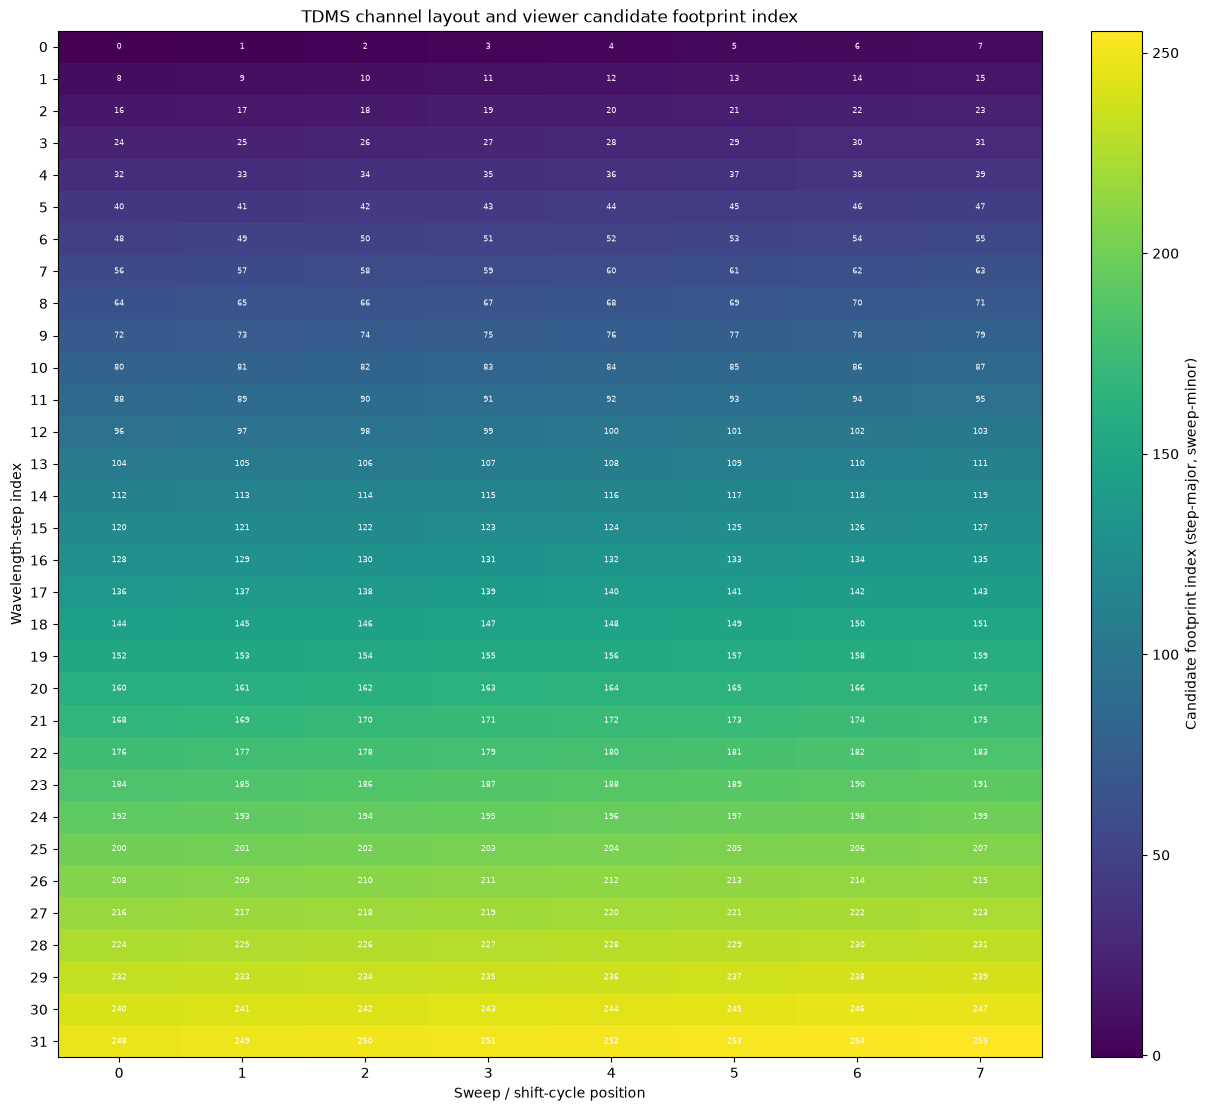

In [4]:
layout = analyze_channel_layout(inventory)
layout_rows = []
for channel in layout["channels"]:
    row = {key: value for key, value in channel.items() if key != "properties"}
    row["channel_property_keys"] = ", ".join(channel["properties"])
    layout_rows.append(row)
channel_layout_df = pd.DataFrame(layout_rows)
channel_layout_df.to_csv(OUTPUT_DIR / "channel_layout.csv", index=False)

layout_summary = {key: value for key, value in layout.items() if key != "channels"}
display(pd.Series(layout_summary, name="observed TDMS layout"))
display(channel_layout_df.head(12))

if layout["steps_per_sweep"] and layout["sweeps_per_cycle"]:
    steps = layout["steps_per_sweep"]
    sweeps = layout["sweeps_per_cycle"]
    index_grid = np.full((steps, sweeps), np.nan)
    for channel in layout["channels"]:
        if channel["footprint_index"] is not None and channel["layout_status"] == "ok":
            index_grid[channel["step"], channel["sweep"]] = channel["footprint_index"]
    fig, ax = plt.subplots(figsize=(12, 11), constrained_layout=True)
    image = ax.imshow(index_grid, origin="upper", aspect="auto", cmap="viridis",
                      vmin=-0.5, vmax=max(0.5, steps * sweeps - 0.5))
    for step in range(steps):
        for sweep in range(sweeps):
            value = index_grid[step, sweep]
            label = f"{int(value)}" if np.isfinite(value) else "missing"
            ax.text(sweep, step, label, ha="center", va="center", fontsize=5.5,
                    color="white" if np.isfinite(value) else "red")
    ax.set(xticks=np.arange(sweeps), yticks=np.arange(steps),
           xlabel="Sweep / shift-cycle position", ylabel="Wavelength-step index",
           title="TDMS channel layout and viewer candidate footprint index")
    fig.colorbar(image, ax=ax, label="Candidate footprint index (step-major, sweep-minor)")
    fig.savefig(OUTPUT_DIR / "channel_layout.png", dpi=180)
    plt.show()
    plt.close(fig)
else:
    print("A Step/Sweep layout plot is unavailable because the TDMS metadata did not declare both dimensions.")

## 4. Wavelength evidence grade

A physical wavelength plot is produced only for a complete grade A or B mapping. Step numbers and the instrument's nominal design values are never converted into measured wavelengths.

In [5]:
wavelength = wavelength_evidence(inventory, layout)
wavelength_rows = wavelength["source_properties"]
wavelength_df = pd.DataFrame([{
    "scope": row["scope"], "group": row["group_name"], "channel": row["channel_name"],
    "property": row["property_name"], "raw_type": row["raw_data_type"],
    "raw_value_json": json.dumps(row["raw_value"], ensure_ascii=False, allow_nan=False),
    "unit": row["unit"], "evidence_grade": wavelength["grade"],
} for row in wavelength_rows])
if wavelength_df.empty:
    wavelength_df = pd.DataFrame([{
        "scope": "none", "group": None, "channel": None,
        "property": "No wavelength-related property found", "raw_type": None,
        "raw_value_json": None, "unit": None, "evidence_grade": wavelength["grade"],
    }])
wavelength_df.to_csv(OUTPUT_DIR / "wavelength_evidence.csv", index=False)

display(Markdown(f"**Evidence grade {wavelength['grade']}: {wavelength['label']}**  \n{wavelength['explanation']}"))
if wavelength["source_properties"]:
    display(wavelength_df)
if wavelength["physical_wavelength_available"]:
    wavelength_map_df = pd.DataFrame(wavelength["mapping"]).sort_values("footprint_index")
    display(wavelength_map_df.head(12))
    fig, ax = plt.subplots(figsize=(12, 4.5), constrained_layout=True)
    ax.plot(wavelength_map_df["footprint_index"], wavelength_map_df["wavelength_nm"], ".-", ms=3)
    ax.set(xlabel="Viewer candidate footprint index", ylabel="Wavelength (nm)",
           title=f"Evidence-backed physical wavelength mapping (grade {wavelength['grade']})")
    fig.savefig(OUTPUT_DIR / "wavelength_vs_channel.png", dpi=180)
    plt.show()
    plt.close(fig)
else:
    print("Physical wavelength values: not available / not recoverable from inspected metadata.")
    print("Missing calibration information:", wavelength["missing_calibration_information"])

**Evidence grade C: Scan-step information only**  
Scan/channel indices are present, but the inspected properties do not provide a complete physical wavelength mapping.

,scope,group,channel,property,raw_type,raw_value_json,unit,evidence_grade
0,group,CASALS,None,# WVLSteps/Sweep,int,32,None,C


Physical wavelength values: not available / not recoverable from inspected metadata.
Missing calibration information: ['A per-channel or per-step physical wavelength value with units', 'A wavelength calibration lookup or calibrated start and increment in physical units', 'A tuning-voltage/frequency or beam-steering calibration tied to the channel index']


## 5. Sampling and TX/RX assumptions

The current viewer's sample-rate and TX-cut values are treated as code parameters. Metadata fields expressed in ticks are reported as ticks; waveform shape alone cannot establish their conversion to samples, seconds, or physical range.

In [6]:
viewer_source = (ROOT / "casals_tdms_viewer/tdms_processor.py").read_text(encoding="utf-8")
viewer_sample_rate_match = re.search(r"\bfs\s*=\s*([0-9.eE+-]+)", viewer_source)
viewer_sample_rate_hz = float(viewer_sample_rate_match.group(1)) if viewer_sample_rate_match else None
from casals_tdms_viewer.tdms_processor import CasalsTdmsProcessor
viewer_defaults = CasalsTdmsProcessor()
viewer_parameters = {
    "viewer_default_wavelength_steps_per_sweep": viewer_defaults.wvl_steps_per_sweep,
    "viewer_default_sweeps_per_shift_cycle": viewer_defaults.sweeps_per_cycle,
    "viewer_tx_samples_cut": list(viewer_defaults.tx_samples_cut),
    "viewer_assumed_sample_rate_hz": viewer_sample_rate_hz,
    "viewer_source": "casals_tdms_viewer/tdms_processor.py",
}
display(pd.Series(viewer_parameters, name="existing viewer parameters"))

sample_timing_properties = [row for row in inventory["property_rows"]
                            if re.search(r"sample|sampling|frequency|interval|clock|digitizer|adc|tick|\btx\b|\brx\b",
                                         row["property_name"], re.IGNORECASE)]
if sample_timing_properties:
    display(pd.DataFrame([{
        "scope": row["scope"], "property": row["property_name"],
        "raw_value": row["readable_value"], "unit": row["unit"],
    } for row in sample_timing_properties]))

explicit_sample_rate = [row for row in sample_timing_properties
                        if re.search(r"sample.?rate|sampling.?frequency|sampling.?interval|digitizer.?frequency|adc.?frequency",
                                     row["property_name"], re.IGNORECASE)
                        and row["unit"] in {"hz", "khz", "mhz", "ghz"}]
if explicit_sample_rate:
    print("Explicit sample-rate evidence:", [(row["property_name"], row["raw_value"], row["unit"])
                                               for row in explicit_sample_rate])
else:
    print("Sampling rate assumed by existing viewer; not verified from inspected TDMS metadata.")
print("TX/RX window fields, if present, do not establish sample-index boundaries without a tick-to-sample/time calibration.")

viewer_default_wavelength_steps_per_sweep                                      32
viewer_default_sweeps_per_shift_cycle                                           8
viewer_tx_samples_cut                                                     [8, 68]
viewer_assumed_sample_rate_hz                                        1000000000.0
viewer_source                                casals_tdms_viewer/tdms_processor.py
Name: existing viewer parameters, dtype: object

,scope,property,raw_value,unit
0,group,TxWinWidth(tick),10,tick
1,group,RxWinWidth(tick),341,tick
2,group,SOAtoStartPulseDelay(tick),80,tick
3,group,SOAtoMZMDelay(tick),14,tick
4,group,RxADCDelay(tick),41,tick
5,group,SweepToFirstSOADelay(tick),26,tick
6,group,SOADelay(tick),0,tick


Sampling rate assumed by existing viewer; not verified from inspected TDMS metadata.
TX/RX window fields, if present, do not establish sample-index boundaries without a tick-to-sample/time calibration.


## 6. Bounded raw-waveform samples

Only the selected rows and their sample intervals are read with `channel[start:stop]`. These plots use raw sample index and raw counts. They do not assert sample time, distance, TX/RX alignment, or a detected physical return.

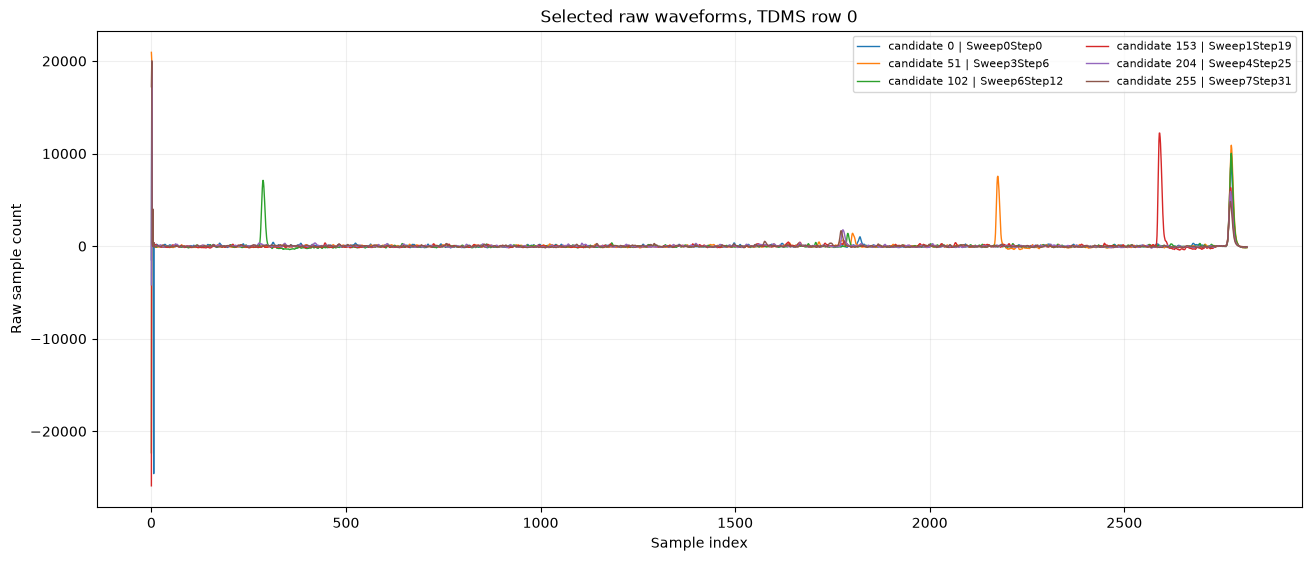

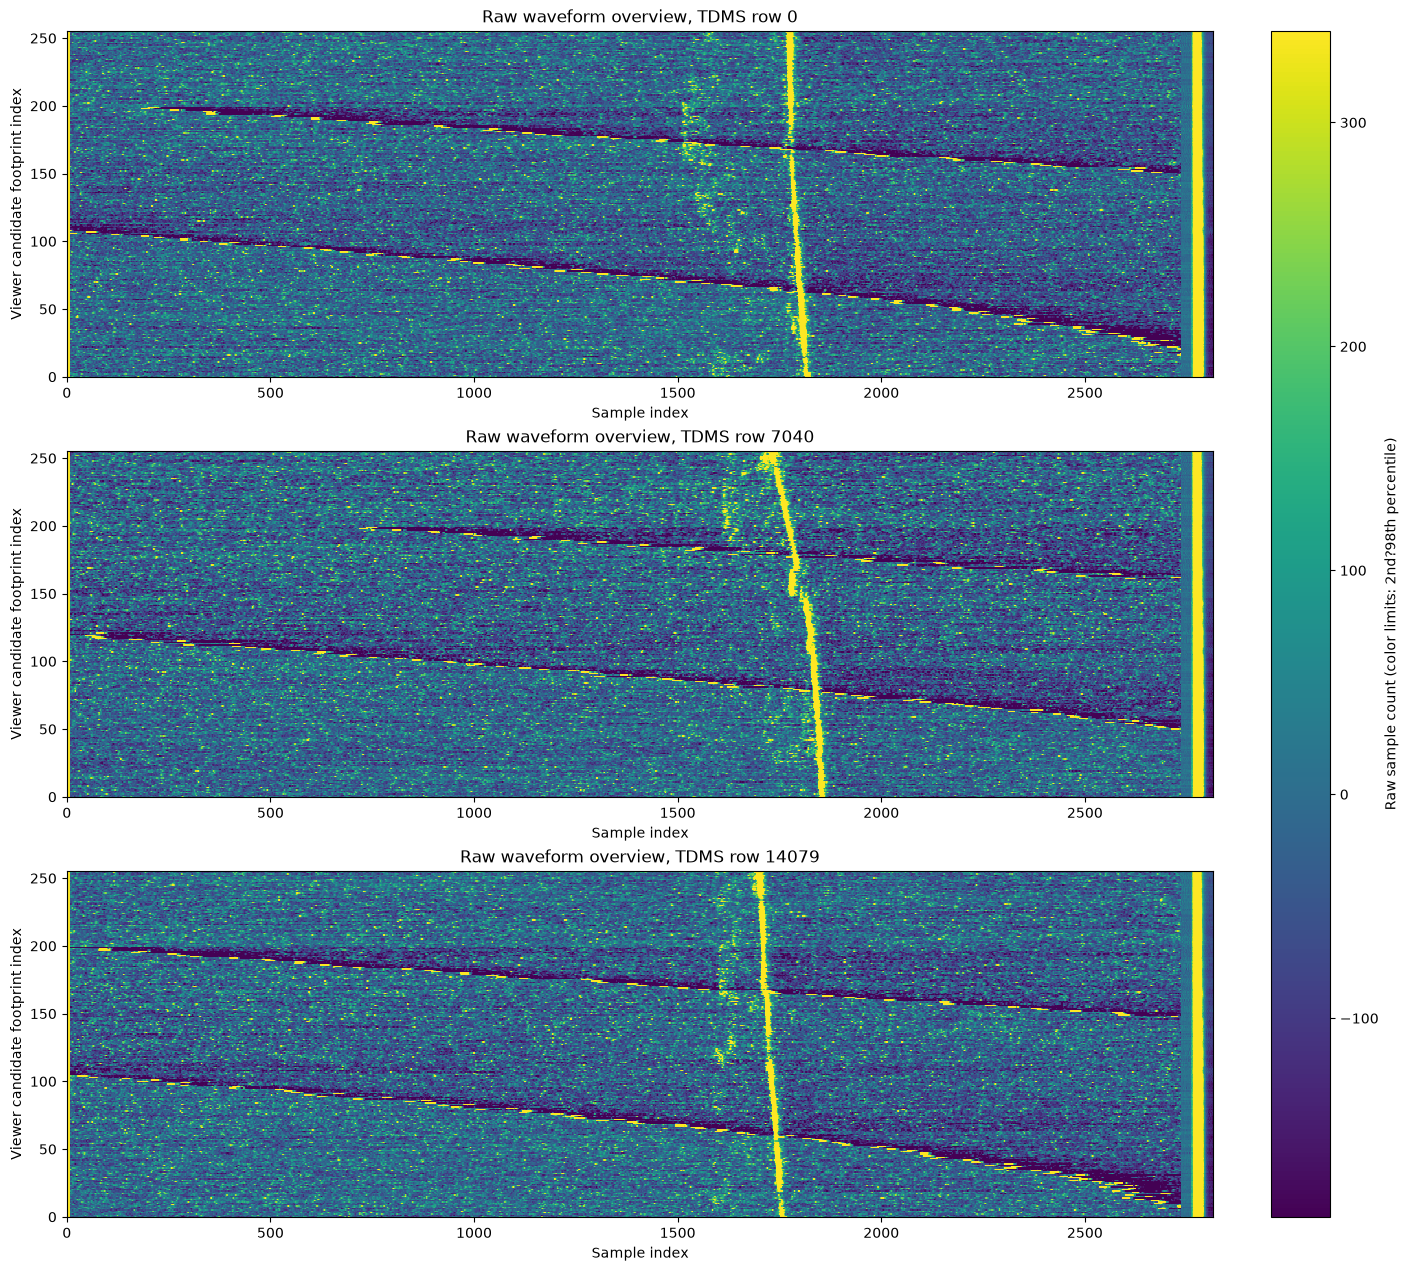

,row_index,footprint_index,channel_name,sweep,step,sample_count,minimum_raw_count,maximum_raw_count,median_raw_count,standard_deviation_raw_count,zero_fraction,max_excursion_from_median_raw_count,dtype_rail_count
73,0,73,Sweep1Step9,1,9,2816,-32655.0,19981.0,-33.0,1118.021241,0.003196,32622.0,0
195,0,195,Sweep3Step24,3,24,2816,-32622.0,19982.0,-73.0,1211.586133,0.004261,32549.0,0
187,0,187,Sweep3Step23,3,23,2816,-427.0,32313.0,-23.0,915.567052,0.007457,32336.0,0
65,0,65,Sweep1Step8,1,8,2816,-317.0,32172.0,-9.0,1058.311666,0.004261,32181.0,0
203,0,203,Sweep3Step25,3,25,2816,-32028.0,19982.0,-12.0,780.053251,0.008168,32016.0,0
81,0,81,Sweep1Step10,1,10,2816,-31951.0,19981.0,-40.5,1085.388816,0.006392,31910.5,0
179,0,179,Sweep3Step22,3,22,2816,-411.0,31704.0,-32.0,894.393989,0.005327,31736.0,0
57,0,57,Sweep1Step7,1,7,2816,-301.0,31458.0,-19.0,978.271392,0.004616,31477.0,0
211,0,211,Sweep3Step26,3,26,2816,-31442.0,19982.0,-8.0,776.540990,0.009588,31434.0,0
89,0,89,Sweep1Step11,1,11,2816,-31252.0,19981.0,-31.0,1025.625351,0.006037,31221.0,0


Selected rows read by slices; row 0 parity with the viewer's step-major output passed.
Sampled row indices: [0, 7040, 14079] | matrix shape: (256, 2816)
Largest sample excursion is a raw-count screening statistic, not a waveform detection.


In [7]:
selected_rows = select_row_indices(layout["rows_per_file"], ROW_INDICES) if layout["rows_per_file"] else []
waveforms_by_row = {}
waveform_stats = []
WAVEFORM_VIEWER_PARITY = None
example_footprints = []
if not layout["layout_complete"] or not layout["samples_per_row"]:
    WAVEFORM_STATUS = "Skipped: channel layout or row/sample shape is incomplete."
    print(WAVEFORM_STATUS)
else:
    n_footprints = layout["footprints_per_row"]
    n_samples = layout["samples_per_row"]
    ordered_channels = sorted(layout["channels"], key=lambda item: item["footprint_index"])
    example_footprints = np.unique(np.linspace(
        0, n_footprints - 1, min(N_EXAMPLE_CHANNELS, n_footprints), dtype=int
    )).tolist()
    wave_tdms = TdmsFile.open(TDMS_FILE)
    try:
        group = wave_tdms[layout["group_name"]]
        for row_index in selected_rows:
            matrix = np.empty((n_footprints, n_samples), dtype=np.dtype(ordered_channels[0]["dtype"]))
            for channel in ordered_channels:
                samples = read_waveform_row(
                    group[channel["name"]], row_index, n_samples, layout["rows_per_file"]
                )
                matrix[channel["footprint_index"], :] = samples
            waveforms_by_row[row_index] = matrix
    finally:
        wave_tdms.close()

    # Compare one bounded raw row with the existing viewer's step-major, cut-waveform output.
    viewer_processor = CasalsTdmsProcessor()
    try:
        viewer_processor.load(TDMS_FILE)
        viewer_row = viewer_processor.extract_vis_swath_row(selected_rows[0])
        head_cut, tail_cut = viewer_processor.tx_samples_cut
        cut_end = n_samples - tail_cut if tail_cut else None
        expected_viewer_row = waveforms_by_row[selected_rows[0]][:, head_cut:cut_end]
        WAVEFORM_VIEWER_PARITY = bool(np.array_equal(viewer_row, expected_viewer_row))
    finally:
        viewer_processor.close()
    if not WAVEFORM_VIEWER_PARITY:
        raise AssertionError("Selected TDMS row does not match the current viewer's step-major output after its configured cut.")
    WAVEFORM_STATUS = "Selected rows read by slices; row 0 parity with the viewer's step-major output passed."

    for row_index, matrix in waveforms_by_row.items():
        integer_limits = np.iinfo(matrix.dtype) if np.issubdtype(matrix.dtype, np.integer) else None
        for channel in ordered_channels:
            values = matrix[channel["footprint_index"]].astype(np.float64)
            median = float(np.median(values))
            stats = {
                "row_index": row_index,
                "footprint_index": channel["footprint_index"],
                "channel_name": channel["name"],
                "sweep": channel["sweep"],
                "step": channel["step"],
                "sample_count": int(values.size),
                "minimum_raw_count": float(np.min(values)),
                "maximum_raw_count": float(np.max(values)),
                "median_raw_count": median,
                "standard_deviation_raw_count": float(np.std(values)),
                "zero_fraction": float(np.mean(values == 0)),
                "max_excursion_from_median_raw_count": float(np.max(np.abs(values - median))),
                "dtype_rail_count": int(np.count_nonzero((values == integer_limits.min) | (values == integer_limits.max)))
                    if integer_limits is not None else None,
            }
            waveform_stats.append(stats)
    waveform_stats_df = pd.DataFrame(waveform_stats)
    waveform_stats_df.to_csv(OUTPUT_DIR / "waveform_sample_statistics.csv", index=False)

    example_row = selected_rows[0]
    example_matrix = waveforms_by_row[example_row]
    fig, ax = plt.subplots(figsize=(13, 5.5), constrained_layout=True)
    for footprint in example_footprints:
        channel = ordered_channels[footprint]
        ax.plot(np.arange(n_samples), example_matrix[footprint], lw=1.0,
                label=f"candidate {footprint} | {channel['name']}")
    ax.set(xlabel="Sample index", ylabel="Raw sample count",
           title=f"Selected raw waveforms, TDMS row {example_row}")
    ax.grid(True, alpha=0.2)
    ax.legend(ncol=2, fontsize=8)
    fig.savefig(OUTPUT_DIR / "waveform_examples.png", dpi=180)
    plt.show()
    plt.close(fig)

    all_values = np.concatenate([matrix.ravel() for matrix in waveforms_by_row.values()]).astype(np.float64)
    color_low, color_high = np.quantile(all_values, [0.02, 0.98])
    if color_low == color_high:
        color_high = color_low + 1.0
    fig, axes = plt.subplots(len(selected_rows), 1, figsize=(14, 4.2 * len(selected_rows)),
                             squeeze=False, constrained_layout=True)
    for ax, row_index in zip(axes[:, 0], selected_rows):
        image = ax.imshow(waveforms_by_row[row_index], origin="lower", aspect="auto",
                          interpolation="nearest", cmap="viridis", vmin=color_low, vmax=color_high)
        ax.set(xlabel="Sample index", ylabel="Viewer candidate footprint index",
               title=f"Raw waveform overview, TDMS row {row_index}")
    fig.colorbar(image, ax=axes[:, 0].tolist(), label="Raw sample count (color limits: 2nd?98th percentile)")
    fig.savefig(OUTPUT_DIR / "waveform_overview.png", dpi=180)
    plt.show()
    plt.close(fig)

    display(waveform_stats_df.loc[waveform_stats_df["row_index"] == example_row].sort_values(
        "max_excursion_from_median_raw_count", ascending=False
    ).head(10))
    print(WAVEFORM_STATUS)
    print("Sampled row indices:", selected_rows, "| matrix shape:", example_matrix.shape)
    print("Largest sample excursion is a raw-count screening statistic, not a waveform detection.")

## 7. How L0 relates to L1B

L0 stores raw waveform channels named by Step and Sweep. The viewer arranges them into a candidate footprint axis. L1B exposes geolocated sweep/track records, split `tx_waveform` and `rx_waveform` arrays, and beam geometry. Establishing a correspondence requires source provenance and a verified reshape/order convention; equal counts such as 256 channels or tracks are insufficient.

This run does not select an L1B H5, so no L0?L1B pairing is claimed. The inspected TDMS metadata contains scan indices and acquisition timing/window fields but no physical wavelength mapping. A wavelength value may be absent from the L1B product if it was not propagated during processing; the files inspected here do not identify the processing stage where that information may have been dropped.

## 8. Findings and Limitations

The final report distinguishes file evidence, viewer assumptions, sampled waveform observations, and unverified L1B correspondence. It records no physical wavelength values for grades C or D.

In [8]:
group_props = inventory["groups"][0]["properties"] if inventory["groups"] else {}
frame_key = next((key for key in group_props if re.sub(r"[^a-z0-9]", "", key.lower()) == "sweepsframe"), None)
sweeps_per_frame = group_props.get(frame_key) if frame_key else None
try:
    frame_size = int(sweeps_per_frame)
except (TypeError, ValueError):
    frame_size = None
frame_divisible = (
    layout["rows_per_file"] % frame_size == 0
    if frame_size and layout["rows_per_file"] is not None else None
)
if frame_divisible is False:
    frame_interpretation = (
        "File rows are not divisible by the declared Sweeps/Frame if that field is a row count per frame; "
        "frame semantics are unverified, so this remains an unresolved relationship and not a layout failure."
    )
elif frame_divisible is True:
    frame_interpretation = (
        "File rows are divisible by the declared Sweeps/Frame; the field's frame-boundary semantics remain unverified."
    )
else:
    frame_interpretation = "No positive Sweeps/Frame value was available for a row-count comparison."
frame_relationship = {
    "declared_sweeps_per_frame": sweeps_per_frame,
    "rows_per_file": layout["rows_per_file"],
    "rows_divisible_by_frame_size_if_interpreted_as_row_count": frame_divisible,
    "interpretation": frame_interpretation,
}
file_properties = inventory["file_properties"]
channel_layout_status = {
    key: value for key, value in layout.items()
    if key not in {"channels"}
}
waveform_summary = {
    "status": WAVEFORM_STATUS,
    "row_indices_read": selected_rows,
    "samples_per_row": layout["samples_per_row"],
    "sample_count_per_row_read": layout["samples_per_row"],
    "example_footprints": example_footprints,
    "full_file_waveform_scan": False,
}
summary = {
    "input": {
        "path": TDMS_FILE.relative_to(ROOT).as_posix() if TDMS_FILE.is_relative_to(ROOT) else str(TDMS_FILE),
        "file_name": TDMS_FILE.name,
        "size_bytes": TDMS_FILE.stat().st_size,
        "file_properties": file_properties,
    },
    "tdms_counts": {
        "groups": len(inventory["groups"]),
        "channels": sum(len(group["channels"]) for group in inventory["groups"]),
        "properties": len(inventory["property_rows"]),
    },
    "scan_parameters": {
        "wavelength_steps_per_sweep": layout["steps_per_sweep"],
        "sweeps_per_shift_cycle": layout["sweeps_per_cycle"],
        "footprint_positions_per_row": layout["footprints_per_row"],
        "rows_per_file": layout["rows_per_file"],
        "samples_per_row": layout["samples_per_row"],
        "frame_relationship": frame_relationship,
        "group_properties": group_props,
    },
    "channel_layout": channel_layout_status,
    "viewer_indexing": {
        "formula": "footprint_index = step * sweeps_per_cycle + sweep",
        "channel_order_in_file": layout["channel_order_in_file"],
        "file_order_matches_step_major_then_sweep": layout["file_order_matches_step_major_then_sweep"],
        "layout_consistent_with_observed_TDMS": layout["layout_complete"],
        "sampled_row_parity_with_viewer": WAVEFORM_VIEWER_PARITY,
        "L1B_track_num_correspondence_verified": False,
    },
    "wavelength_evidence": wavelength,
    "sampling_and_waveform": {
        "viewer_parameters": viewer_parameters,
        "sample_rate_statement": (
            "Explicit sample-rate property found; inspect listed metadata for its scope."
            if explicit_sample_rate else
            "Sampling rate assumed by existing viewer; not verified from inspected TDMS metadata."
        ),
        "timing_and_window_properties": [{
            "property": row["property_name"], "value": row["readable_value"], "unit": row["unit"]
        } for row in sample_timing_properties],
        "waveform_sample": waveform_summary,
    },
    "l0_l1b_pairing": {
        "status": "not checked; no matching L1B H5 was explicitly supplied",
        "same_channel_count_is_sufficient_evidence": False,
    },
    "limitations": [
        "No wavelength is inferred from a Step/Sweep or footprint index.",
        "Without a physical wavelength mapping, this file alone cannot support wavelength-attributed spectral comparisons or calibrated radiometric interpretation; gain and response calibration are absent from the inspected metadata.",
        "No physical time, range, TX/RX boundary, or pulse geolocation is inferred from sample shape alone.",
        "Waveform statistics use only the selected rows; they are not full-file statistics.",
        "L0 channel index to L1B track_num mapping has not been validated against a provenance-matched H5.",
    ],
}
if frame_divisible is False:
    summary["limitations"].append(frame_interpretation)

artifact_names = [
    "metadata_inventory.json", "property_inventory.csv", "channel_layout.csv",
    "wavelength_evidence.csv", "audit_summary.json", "audit_summary.md", "channel_layout.png",
]
artifact_names += [
    name for name in ("waveform_examples.png", "waveform_overview.png", "waveform_sample_statistics.csv")
    if (OUTPUT_DIR / name).is_file()
]
if wavelength["physical_wavelength_available"]:
    artifact_names.append("wavelength_vs_channel.png")
summary["outputs"] = [name for name in artifact_names if (OUTPUT_DIR / name).is_file() or name in {"audit_summary.json", "audit_summary.md"}]

(OUTPUT_DIR / "audit_summary.json").write_text(
    json.dumps(summary, indent=2, ensure_ascii=False, allow_nan=False, default=str), encoding="utf-8"
)

group_props = inventory["groups"][0]["properties"] if inventory["groups"] else {}
physical_wavelength = (
    "A physical mapping is available; see the saved wavelength evidence table and plot."
    if wavelength["physical_wavelength_available"]
    else "not available / not recoverable from inspected metadata."
)
missing_calibration = "; ".join(wavelength["missing_calibration_information"]) or "None identified by this audit."
layout_line = (
    f"{layout['steps_per_sweep']} steps x {layout['sweeps_per_cycle']} sweeps = "
    f"{layout['footprints_per_row']} candidate positions; complete={layout['layout_complete']}."
)
lines = [
    "# CASALS L0 TDMS audit summary", "",
    f"- **Input:** `{summary['input']['path']}` ({summary['input']['size_bytes']:,} bytes)",
    f"- **Groups / channels / properties:** {summary['tdms_counts']['groups']} / {summary['tdms_counts']['channels']} / {summary['tdms_counts']['properties']}",
    f"- **Declared scan layout:** {layout_line}",
    f"- **Rows / samples per row:** {layout['rows_per_file']} / {layout['samples_per_row']}",
    f"- **Sweeps/Frame:** {sweeps_per_frame}; {frame_interpretation}",
    f"- **Channel layout checks:** missing={len(layout['missing_step_sweep'])}, duplicate={len(layout['duplicate_step_sweep'])}, extra={len(layout['extra_step_sweep'])}, unrecognized={len(layout['unrecognized_channels'])}, consistent_lengths={layout['channel_lengths_consistent']}.",
    f"- **Wavelength evidence:** Grade {wavelength['grade']}: {wavelength['label']}. {physical_wavelength}",
    f"- **Wavelength evidence basis:** {wavelength['explanation']}",
    f"- **Missing calibration information:** {missing_calibration}",
    f"- **Viewer sample rate:** {viewer_sample_rate_hz} Hz assumed; metadata check: {summary['sampling_and_waveform']['sample_rate_statement']}",
    f"- **Viewer TX sample cut:** `{tuple(viewer_defaults.tx_samples_cut)}`; physical TX/RX boundaries are not verified by this metadata audit.",
    f"- **Sampled rows:** {selected_rows}; {WAVEFORM_STATUS}",
    f"- **Channel order:** source list is {layout['channel_order_in_file']}; viewer row parity after its configured cut={WAVEFORM_VIEWER_PARITY}.",
    "- **L0-to-L1B pairing:** Not checked; no matching L1B H5 was explicitly supplied. The viewer candidate index is not a validated `track_num` mapping.",
    "", "## Group properties", "",
    "```json", json.dumps(group_props, indent=2, ensure_ascii=False, default=str), "```",
    "", "## Interpretation", "",
    "A 256-position Step/Sweep layout establishes channel organization only. It does not supply 256 physical wavelengths. The sampled waveforms are raw counts at sample index; no sample-time or distance axis is asserted.",
    "Without a physical wavelength map, this file alone cannot support wavelength-attributed spectral comparisons or calibrated radiometric interpretation; gain and response calibration are absent from the inspected metadata.",
    "",
]
(OUTPUT_DIR / "audit_summary.md").write_text("\n".join(lines), encoding="utf-8")

display(Markdown(f"""
### Evidence summary

- **Input:** `{summary['input']['file_name']}`
- **TDMS structure:** {summary['tdms_counts']['groups']} group(s), {summary['tdms_counts']['channels']} channels, {summary['tdms_counts']['properties']} metadata properties.
- **Step/Sweep:** {layout_line}
- **Frame field:** {sweeps_per_frame}; {frame_interpretation}
- **Layout completeness:** {layout['layout_complete']}
- **Wavelength evidence:** Grade **{wavelength['grade']}** ? {wavelength['label']}. {physical_wavelength}
- **L0-to-L1B indexing:** not verified; no matching H5 was provided.
- **Waveform reads:** {WAVEFORM_STATUS}

See `audit_summary.md` and `audit_summary.json` in `{OUTPUT_DIR}` for the complete findings and limitations.
"""))
print("Saved audit artifacts:", summary["outputs"])


### Evidence summary

- **Input:** `casals_18-11-2024_13-34-53_158-003.tdms`
- **TDMS structure:** 1 group(s), 256 channels, 13 metadata properties.
- **Step/Sweep:** 32 steps x 8 sweeps = 256 candidate positions; complete=True.
- **Frame field:** 100; File rows are not divisible by the declared Sweeps/Frame if that field is a row count per frame; frame semantics are unverified, so this remains an unresolved relationship and not a layout failure.
- **Layout completeness:** True
- **Wavelength evidence:** Grade **C** ? Scan-step information only. not available / not recoverable from inspected metadata.
- **L0-to-L1B indexing:** not verified; no matching H5 was provided.
- **Waveform reads:** Selected rows read by slices; row 0 parity with the viewer's step-major output passed.

See `audit_summary.md` and `audit_summary.json` in `C:\Users\zhong267\OneDrive - purdue.edu\CASALS\outputs\notebooks\data\tdms_audit\casals_18-11-2024_13-34-53_158-003` for the complete findings and limitations.


Saved audit artifacts: ['metadata_inventory.json', 'property_inventory.csv', 'channel_layout.csv', 'wavelength_evidence.csv', 'audit_summary.json', 'audit_summary.md', 'channel_layout.png', 'waveform_examples.png', 'waveform_overview.png', 'waveform_sample_statistics.csv']
